# Regression 2.1 — chronological comparison
This notebook runs the same analysis as `src/run_analysis.py`. Read `../README.md` and `../DATA_NOTES.md` before interpreting results.
Model selection uses expanding date blocks within the 72 group-stage matches. The 32 knockout matches are a previously inspected retrospective evaluation, not an untouched test.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT / "Linear regression 2.1"
sys.path.insert(0, str(ROOT / "src"))
from run_analysis import run
comparison, results = run()
comparison

                 MAE   RMSE     R2
model                             
Random forest  1.471  1.819  0.233
Ridge          1.503  1.831  0.222
Lasso          1.635  2.022  0.061
Mean baseline  1.829  2.246 -0.170
OLS            1.844  2.253 -0.332
Huber          2.111  2.697 -0.959
{
  "selected_linear_model": "Ridge",
  "selection_rule": "Lowest mean chronological development-fold MAE among linear candidates",
  "development_rows": 72,
  "retrospective_rows": 32,
  "retrospective_metrics": {
    "MAE": 1.1667015337914735,
    "RMSE": 1.4867150903177395,
    "R2": 0.10996088005773974
  },
  "parameters": {
    "ridge__alpha": 3.1622776601683795
  },
  "limitations": [
    "Knockout outcomes were inspected in the previous analysis: not an untouched test.",
    "Features update with results available before each match; this is not a forecast of the entire knockout stage made at its start.",
    "Stage is constant in group-stage training; its effect cannot be estimated.",
    "Source provena

,MAE,RMSE,R2
model,,,
Random forest,1.471237,1.819497,0.232931
Ridge,1.503238,1.831377,0.222034
Lasso,1.635185,2.022338,0.061228
Mean baseline,1.828827,2.246093,-0.170084
OLS,1.843721,2.253496,-0.332332
Huber,2.111272,2.697451,-0.958530


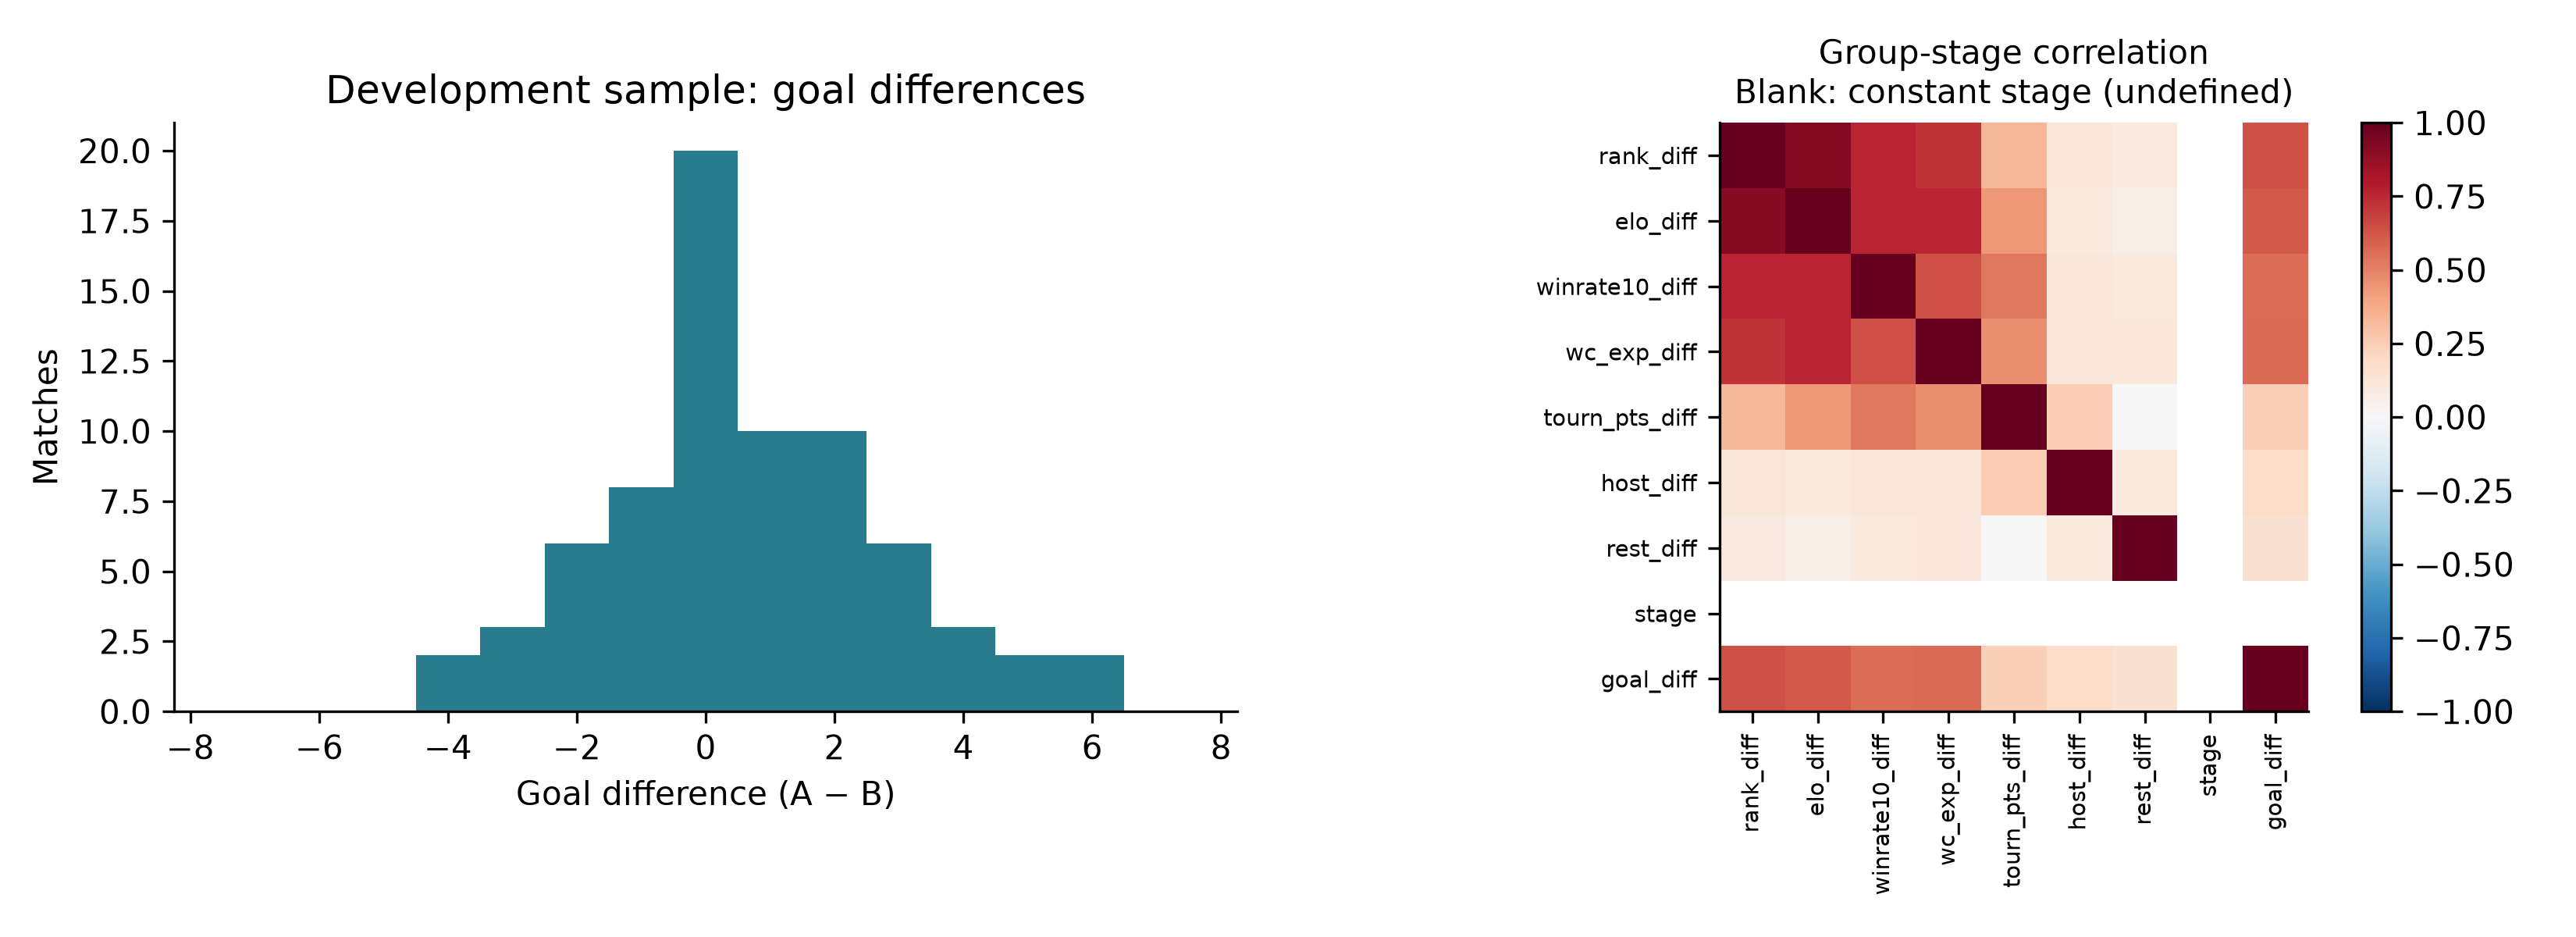

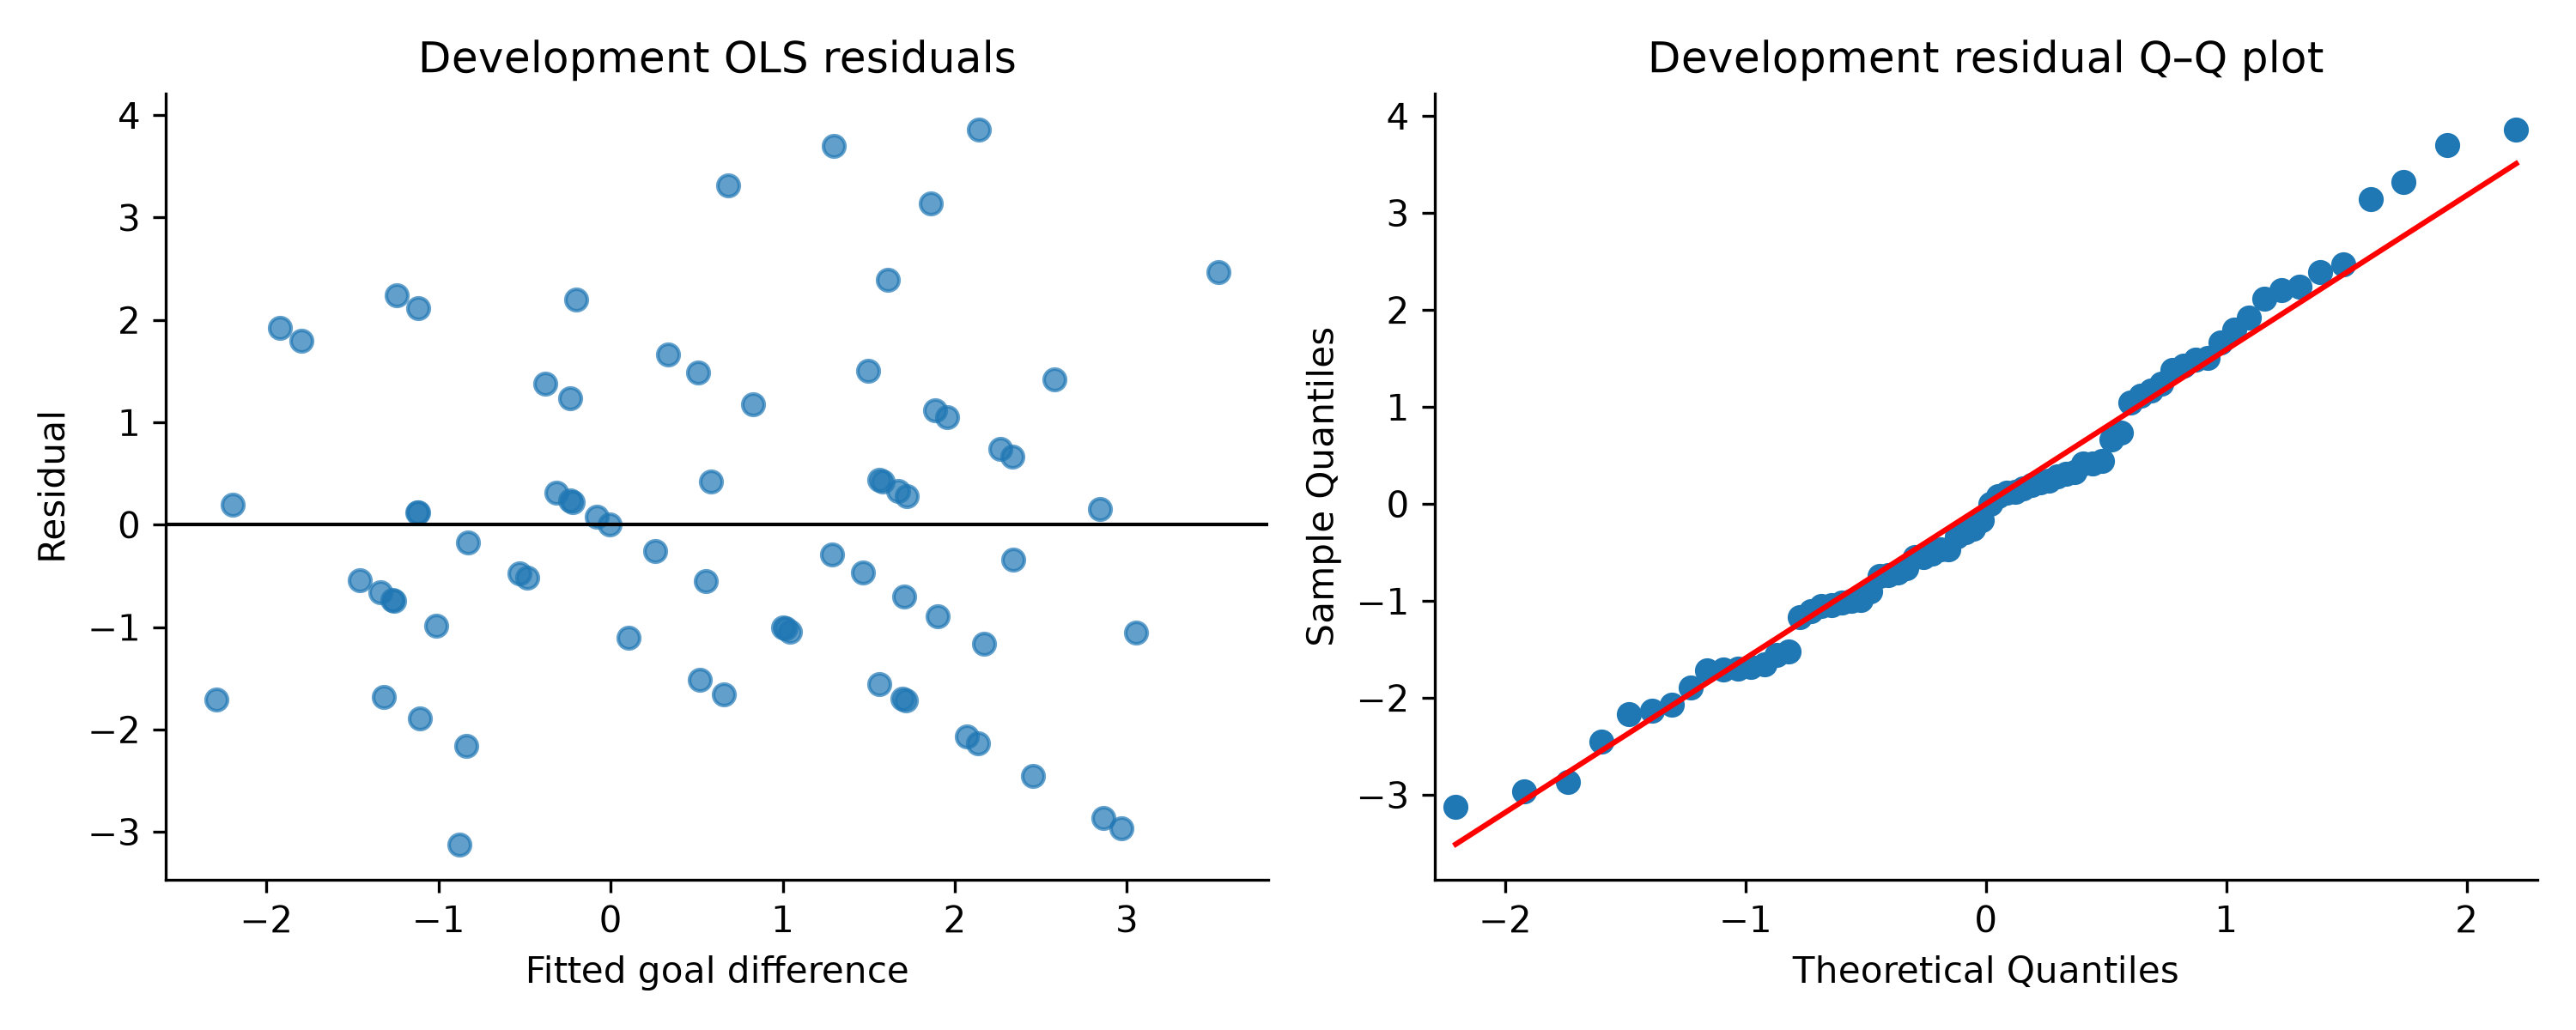

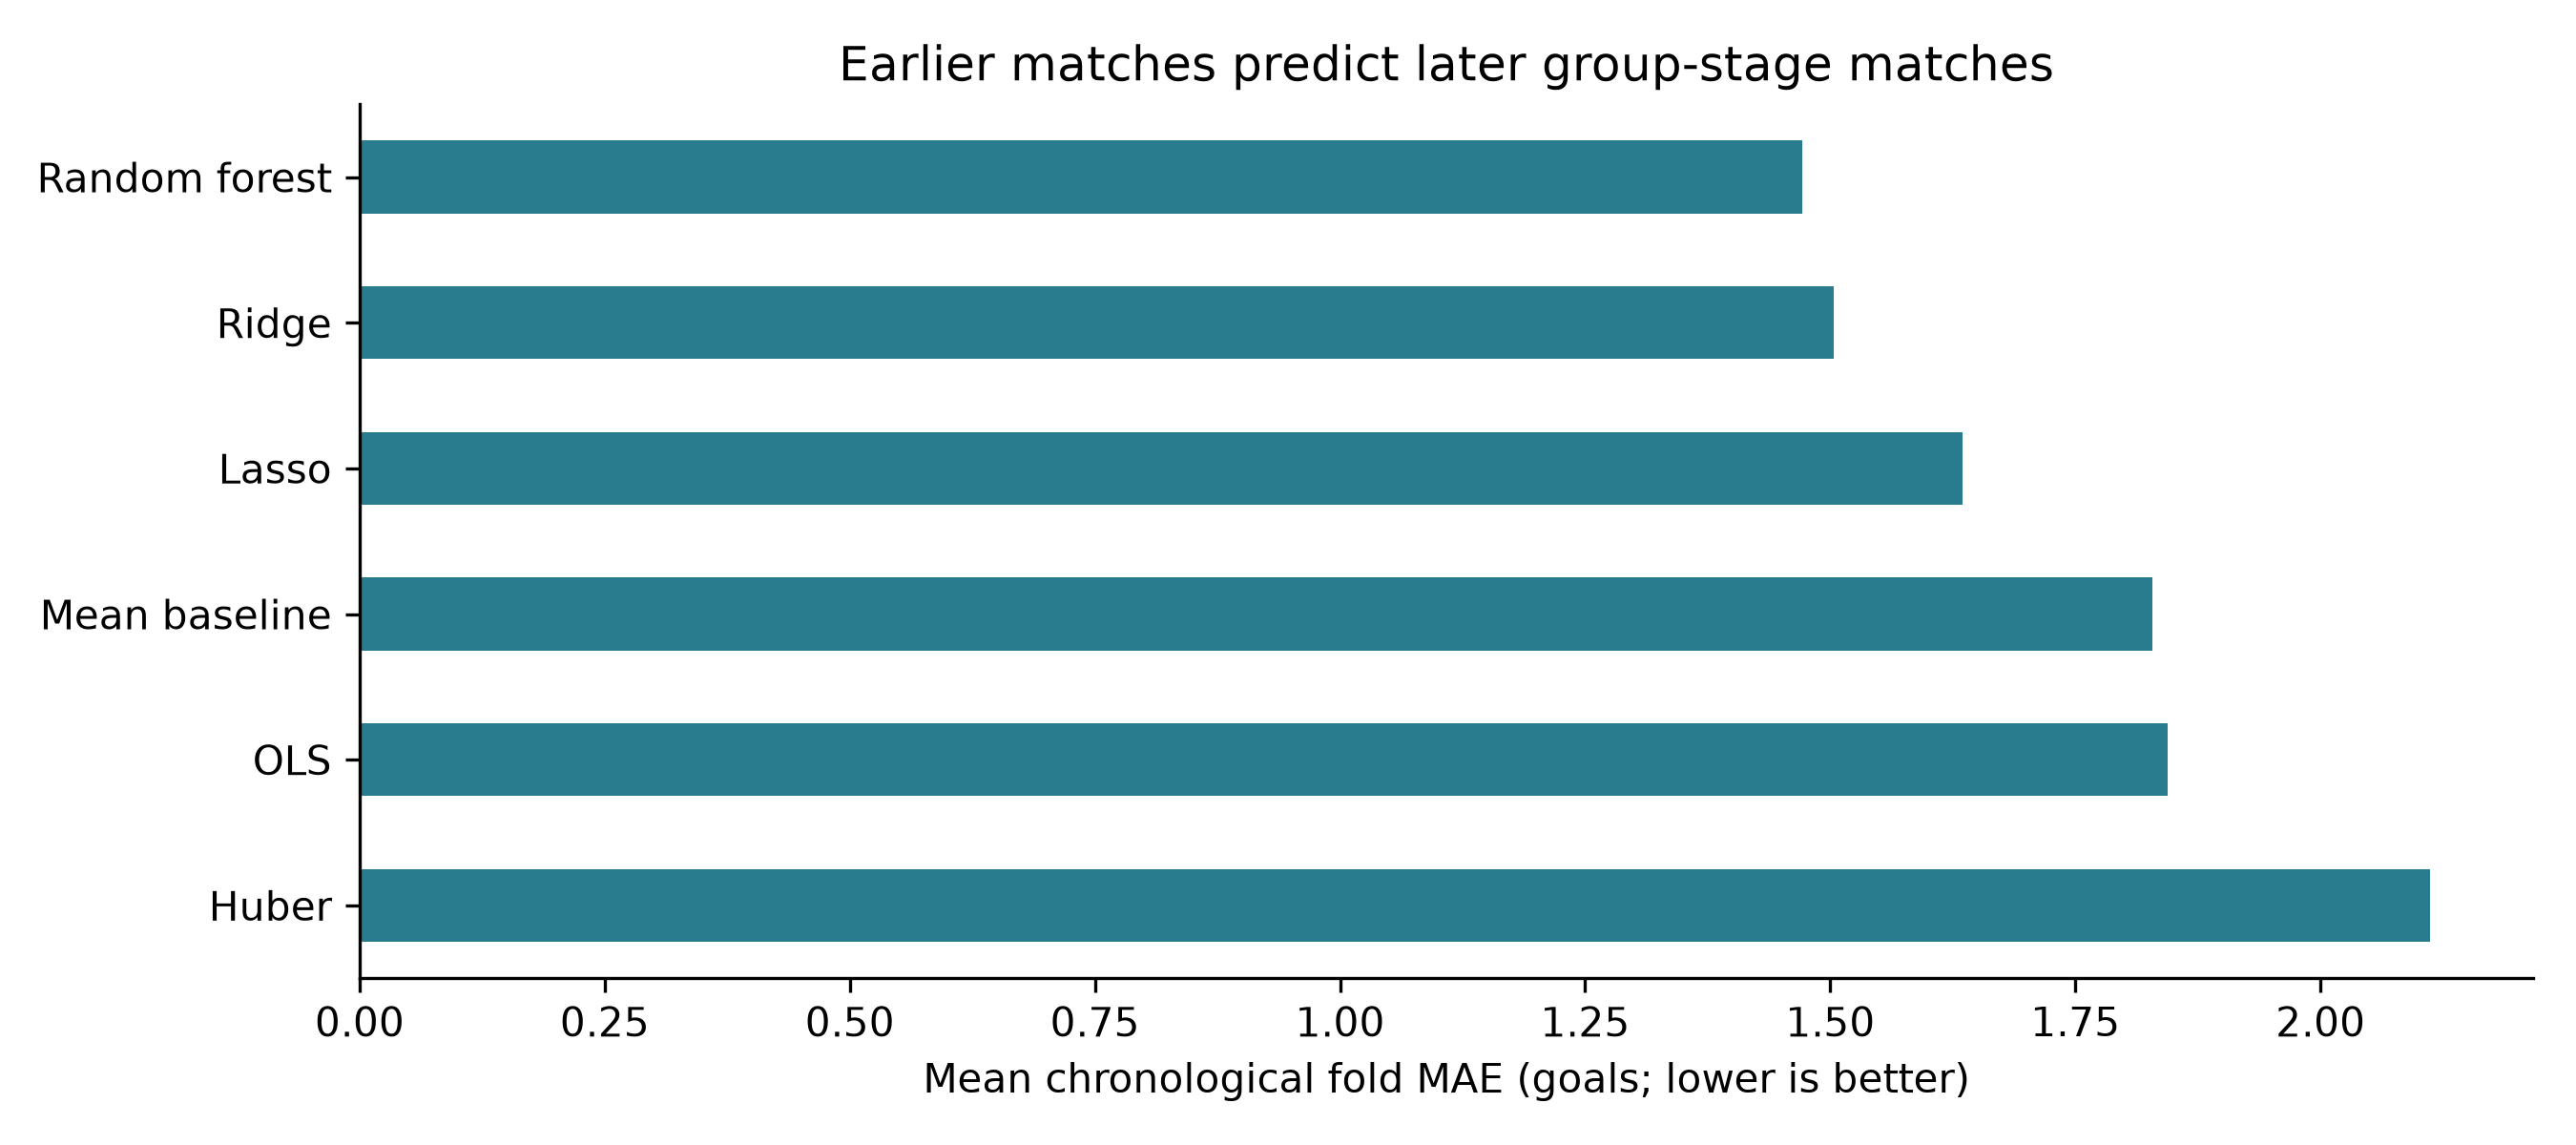

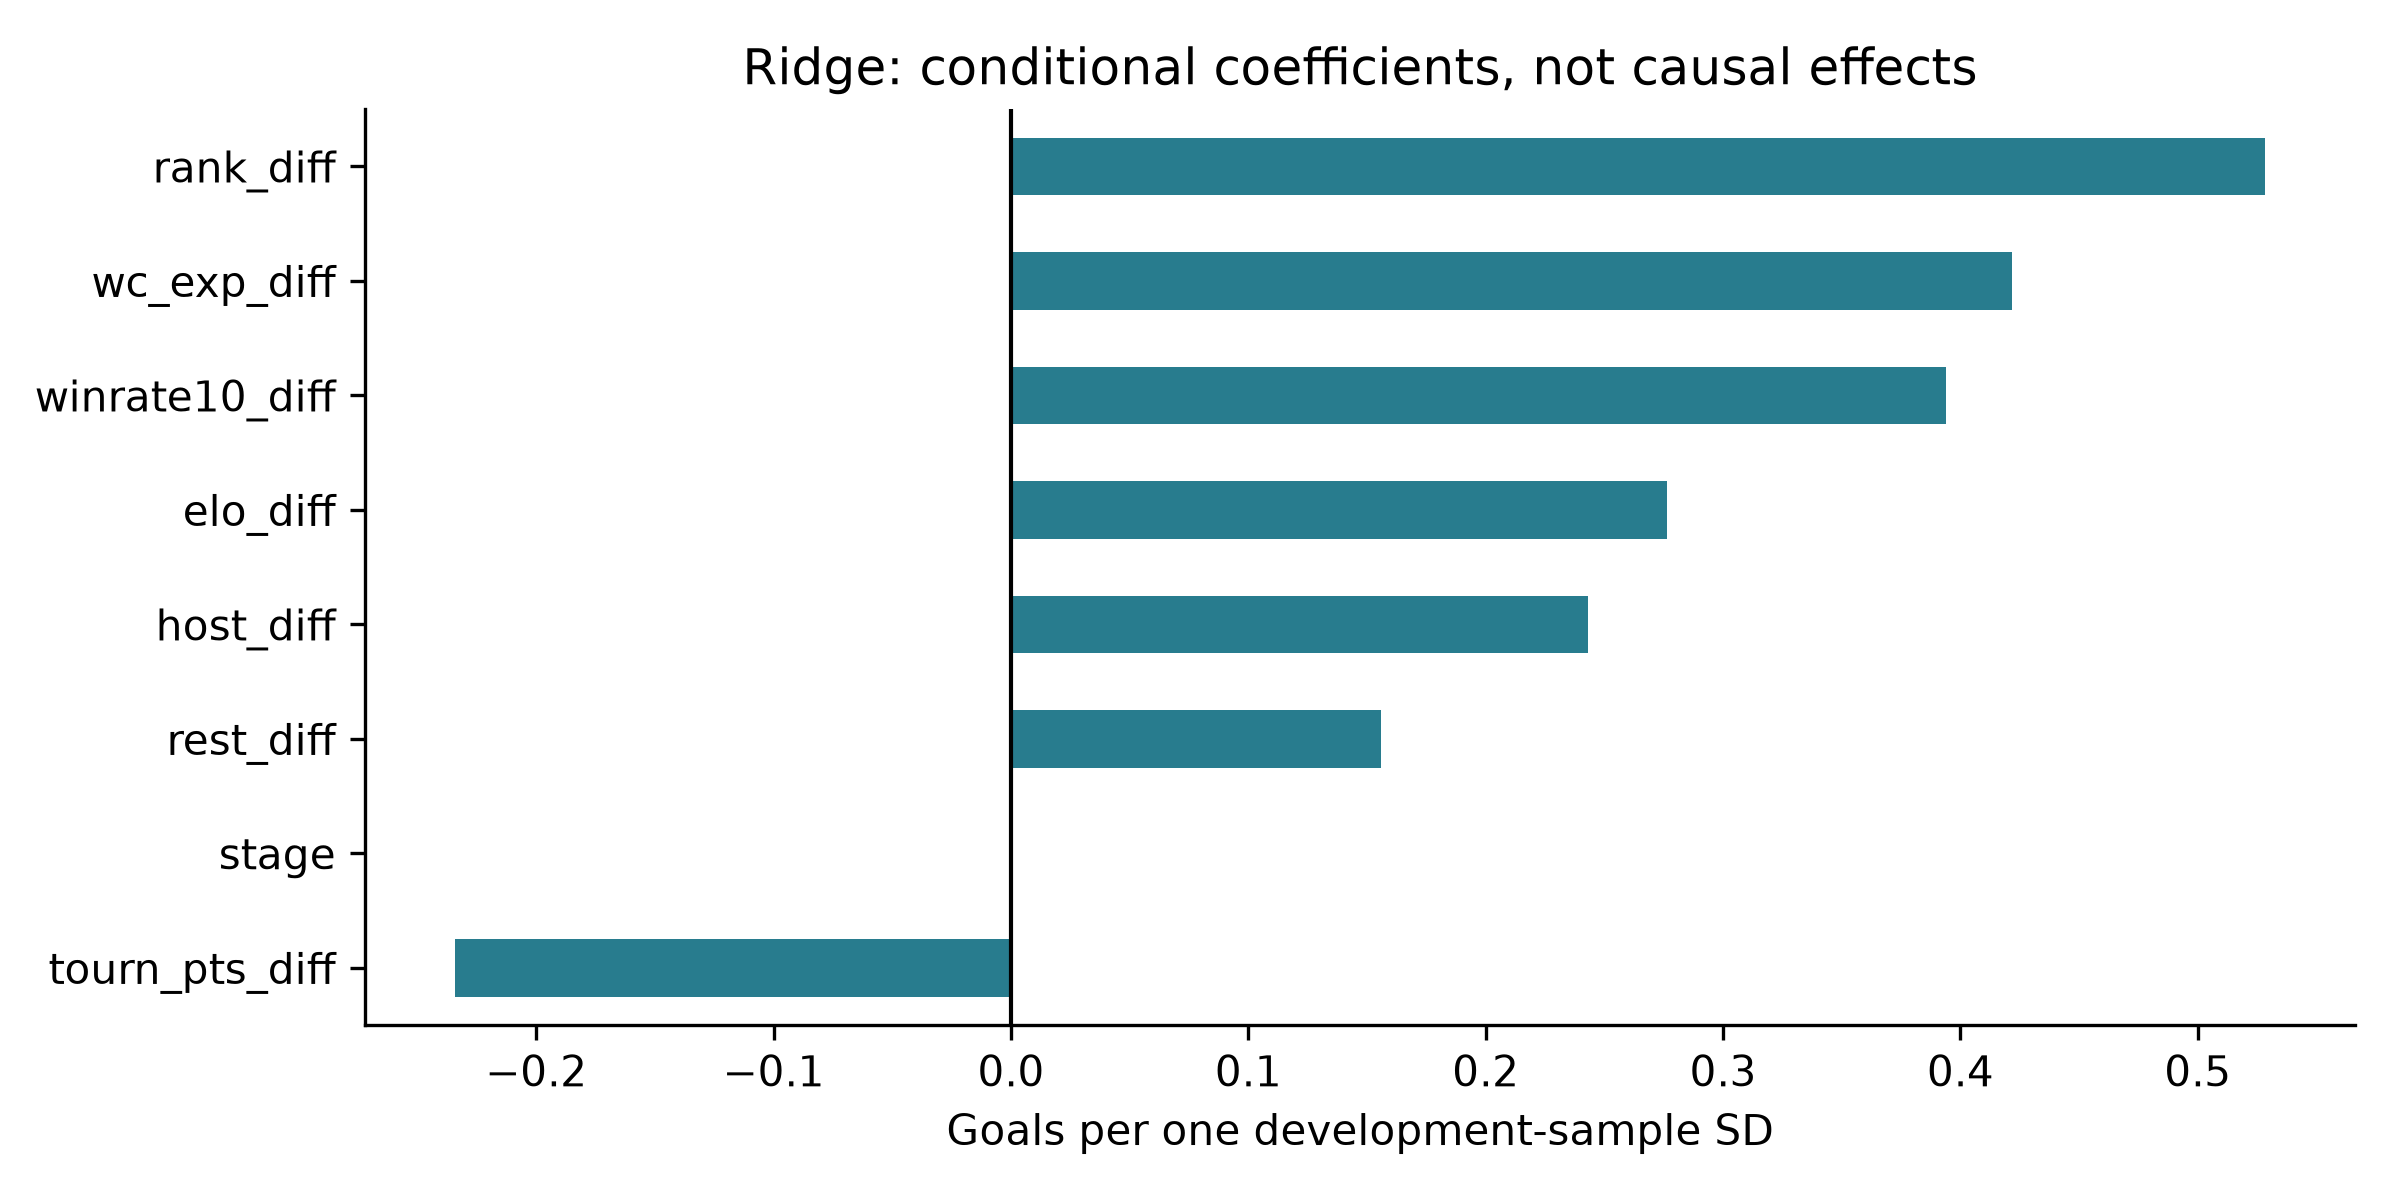

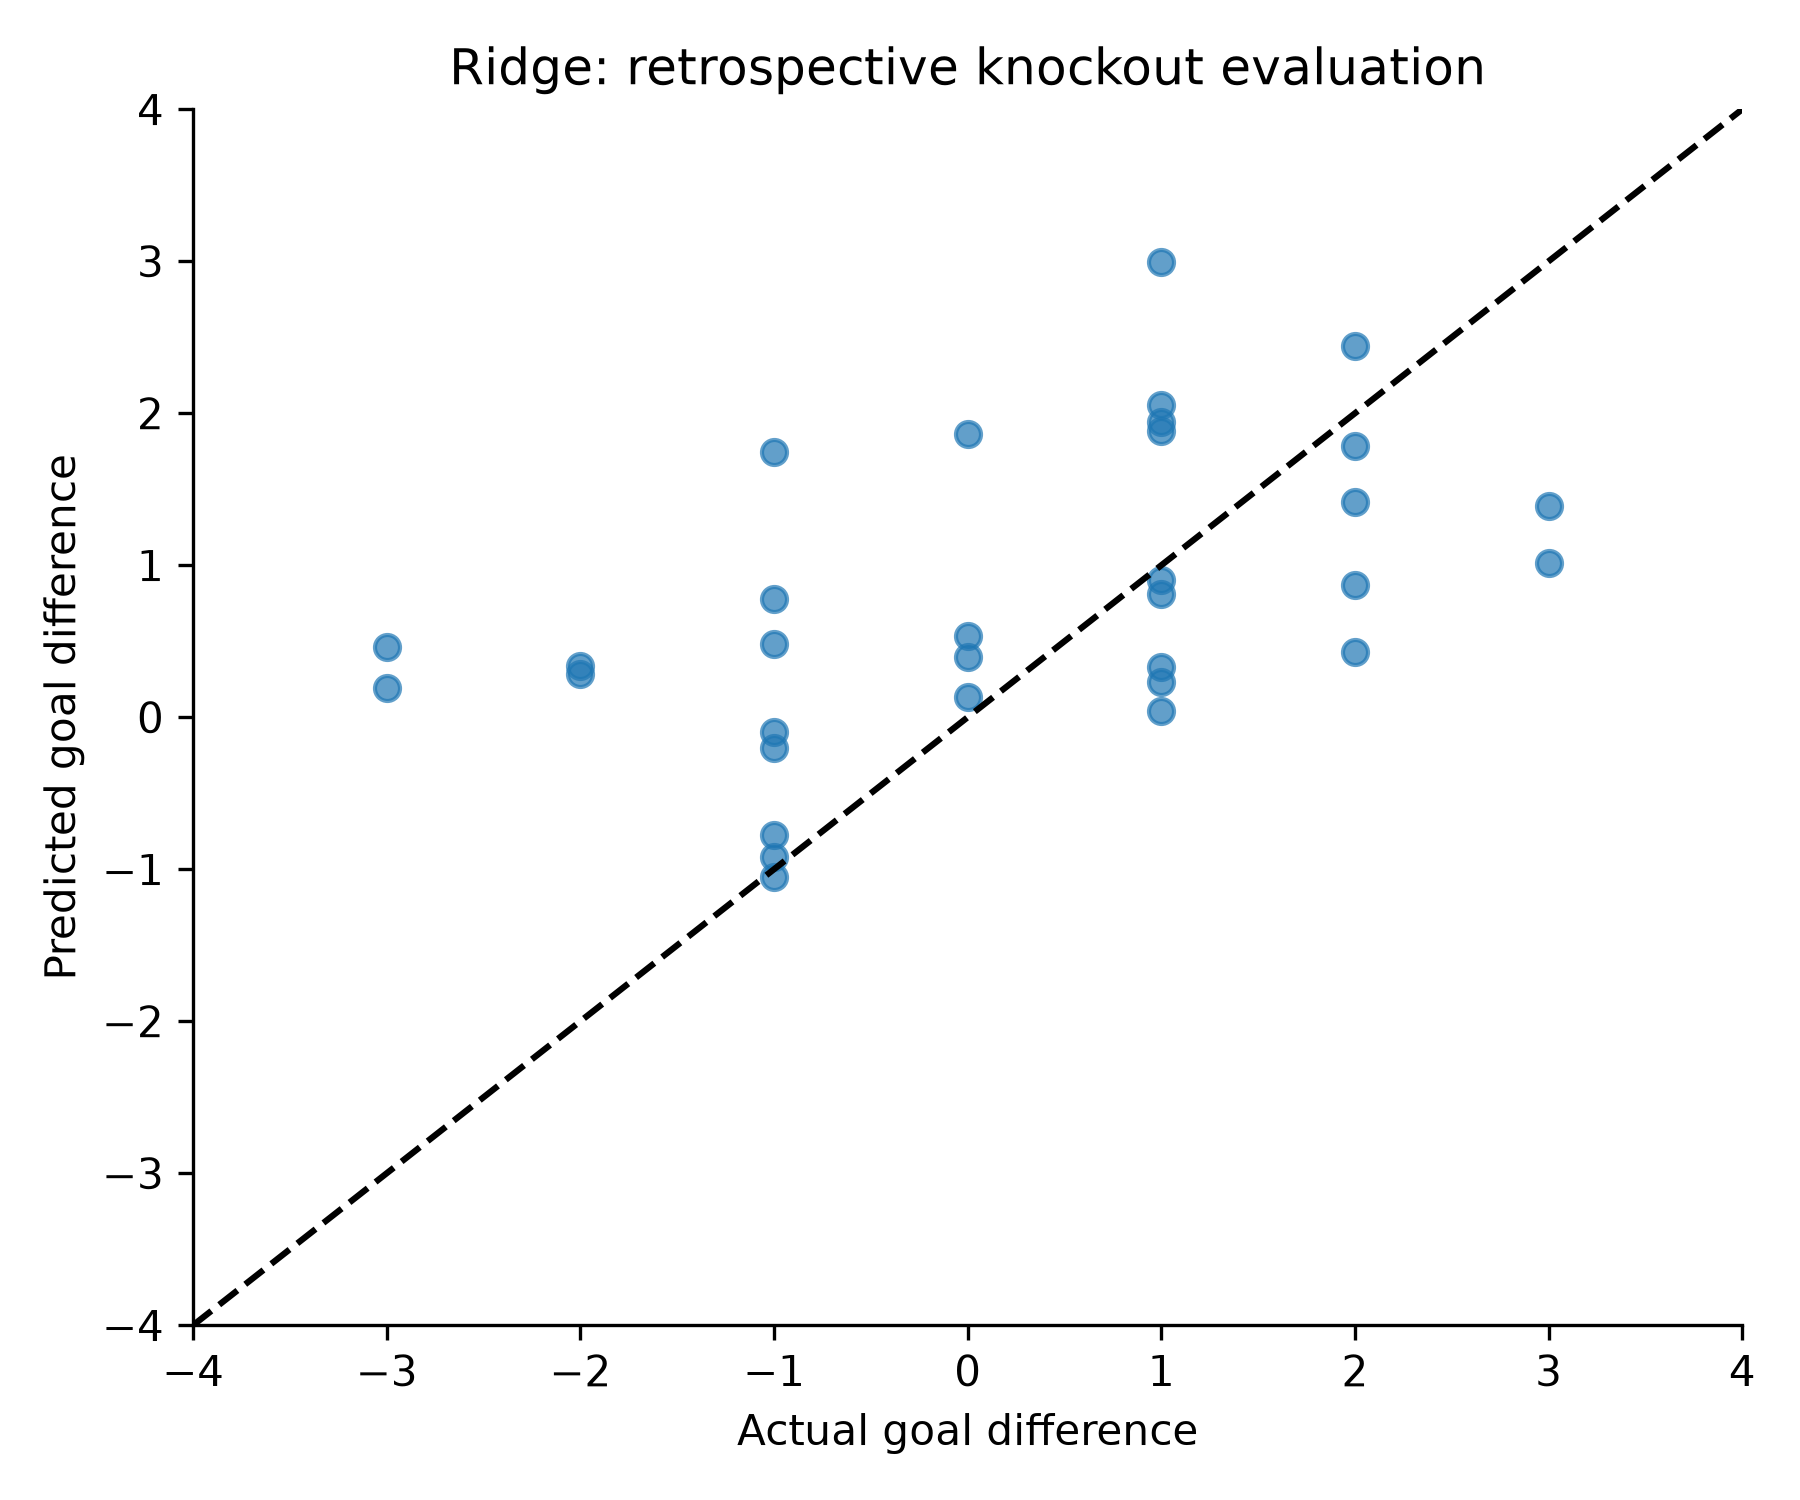

In [2]:
from IPython.display import Image, display
for name in ["fig1_eda.png", "fig2_ols_diagnostics.png", "fig3_cv_comparison.png", "fig4_coefficients.png", "fig6_pred_vs_actual.png"]:
    display(Image(filename=str(ROOT / "figures" / name)))

## Interpretation checklist
Explain the development MAE comparison, the selected linear model, the retrospective MAE/RMSE/R², and why these are different evaluations. Do not infer causation from coefficients or significance from a small score difference. Stage is constant in development and cannot contribute a learned effect. Source gaps remain unresolved. Write the assessed report in your own words.